# 4. Geometric Transformations, Homographies and Stitching

Practice for the image stitching module: what a 2×2 matrix can and cannot do, homogeneous coordinates (with
the quiz examples), estimating a homography from point pairs (DLT, 4 pairs minimum, more pairs for
robustness), RANSAC with outliers, inverse warping and a two-image mosaic with an exposure seam and feathering.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 4.1 Linear vs projective

A 2×2 matrix (rotation, scale, skew, mirror) keeps parallel lines parallel, so a rectangle can only become a
parallelogram. Translation needs a 3×3 matrix in homogeneous coordinates, and a full 3×3 homography can turn
the rectangle into a general quadrilateral.

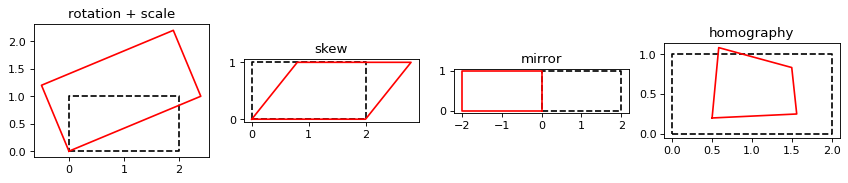

(4, 2, 2) ~ [2. 1. 1.]
T (5, 3) = [ 6 13  2] -> pixel [3.  6.5]
inverse warping g(20, 6) = f(T(20, 6)) = f [52 12]


In [2]:
rect = np.array([[0, 0], [2, 0], [2, 1], [0, 1], [0, 0]], float)
to_h = lambda p: np.c_[p, np.ones(len(p))]
from_h = lambda q: q[:, :2] / q[:, 2:]
mats = {"rotation + scale": np.array([[1.2, -0.5], [0.5, 1.2]]), "skew": np.array([[1, 0.8], [0, 1]]), "mirror": np.array([[-1, 0], [0, 1]])}
Hm = np.array([[1, 0.2, 0.5], [0.1, 1.1, 0.2], [0.3, 0.2, 1.0]])
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (t, M) in zip(axes, mats.items()):
    ax.plot(*rect.T, "k--"); ax.plot(*(rect @ M.T).T, "r"); ax.set_title(t); ax.set_aspect("equal")
axes[3].plot(*rect.T, "k--"); axes[3].plot(*from_h(to_h(rect) @ Hm.T).T, "r"); axes[3].set_title("homography"); axes[3].set_aspect("equal")
plt.show()

print("(4, 2, 2) ~", np.array([4, 2, 2]) / 2)
T = np.array([[1, 0, 1], [0, 4, 1], [0, 0, 2]])
q = T @ [5, 3, 1]; print("T (5, 3) =", q, "-> pixel", q[:2] / q[2])
Ti = np.array([[1, 5, 2], [0, 2, 0], [0, 0, 1]])
print("inverse warping g(20, 6) = f(T(20, 6)) = f", (Ti @ [20, 6, 1])[:2])

## 4.2 Homography from point pairs (DLT)

Each pair gives two linear equations in the 9 entries of H (8 degrees of freedom up to scale), so 4 pairs
are the minimum; with 3 pairs the null space has dimension ≥ 2 and there are infinitely many solutions.
With noisy points, using all pairs in a least-squares fit gives a better estimate than any 4.

In [3]:
def dlt(src, dst):
    rows = []
    for (x, y), (u, v) in zip(src, dst):
        rows.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        rows.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    _, s, Vt = np.linalg.svd(np.array(rows))
    return Vt[-1].reshape(3, 3) / Vt[-1, -1], s

H_true = np.array([[0.9, 0.15, 30], [-0.1, 1.05, 10], [2e-4, 1e-4, 1.0]])
src = rng.uniform(0, 200, (60, 2)); dst = from_h(to_h(src) @ H_true.T)
_, s3 = dlt(src[:3], dst[:3])
print("3 pairs: singular values of the 6x9 system", s3.round(3), "-> 3 null directions, infinitely many H")
H4, _ = dlt(src[:4], dst[:4]); print("4 exact pairs recover H:", np.allclose(H4, H_true))

noisy = dst + rng.normal(0, 1.0, dst.shape)
test = rng.uniform(0, 200, (200, 2)); test_true = from_h(to_h(test) @ H_true.T)
err = lambda H: np.linalg.norm(from_h(to_h(test) @ H.T) - test_true, axis=1).mean()
print(f"noisy points (σ = 1 px): 4 pairs -> mean error {err(dlt(src[:4], noisy[:4])[0]):.2f} px, "
      f"all 60 pairs -> {err(dlt(src, noisy)[0]):.2f} px")

3 pairs: singular values of the 6x9 system [67106.382  8891.116   272.508    69.007    37.549     0.936] -> 3 null directions, infinitely many H
4 exact pairs recover H: True
noisy points (σ = 1 px): 4 pairs -> mean error 3.77 px, all 60 pairs -> 0.43 px


## 4.3 RANSAC

Replace 40% of the matches with random wrong ones. Least squares over all matches is ruined; RANSAC samples
4 pairs, fits H, counts inliers within a threshold, keeps the best and refits on its inliers.

In [4]:
bad = rng.random(60) < 0.4
corrupted = noisy.copy(); corrupted[bad] = rng.uniform(0, 250, (bad.sum(), 2))

def ransac(src, dst, iters=500, thr=3.0):
    best = np.zeros(len(src), bool)
    for _ in range(iters):
        idx = rng.choice(len(src), 4, replace=False)
        H, _ = dlt(src[idx], dst[idx])
        inl = np.linalg.norm(from_h(to_h(src) @ H.T) - dst, axis=1) < thr
        if inl.sum() > best.sum(): best = inl
    return dlt(src[best], dst[best])[0], best

H_r, inl = ransac(src, corrupted)
print(f"{bad.sum()} outliers of 60. least squares on all: {err(dlt(src, corrupted)[0]):.1f} px; "
      f"RANSAC: {err(H_r):.2f} px, inliers {inl.sum()} (true inliers found: {(inl & ~bad).sum()}/{(~bad).sum()}, outliers accepted: {(inl & bad).sum()})")

25 outliers of 60. least squares on all: 197.1 px; RANSAC: 0.38 px, inliers 32 (true inliers found: 32/35, outliers accepted: 0)


## 4.4 Stitching two views

A wide synthetic scene is "photographed" twice: the second view is a homography of the first and has a
different exposure. Inverse warping brings view 2 into view 1's frame. Pasting gives a visible seam (exposure
difference); matching the gain in the overlap and feathering the blend weights hides it.

exposure fit in the overlap: view1 ≈ 1.245 · view2 + -0.059
mean |error| vs the true scene: hard seam 0.0304, gain + feather 0.0029


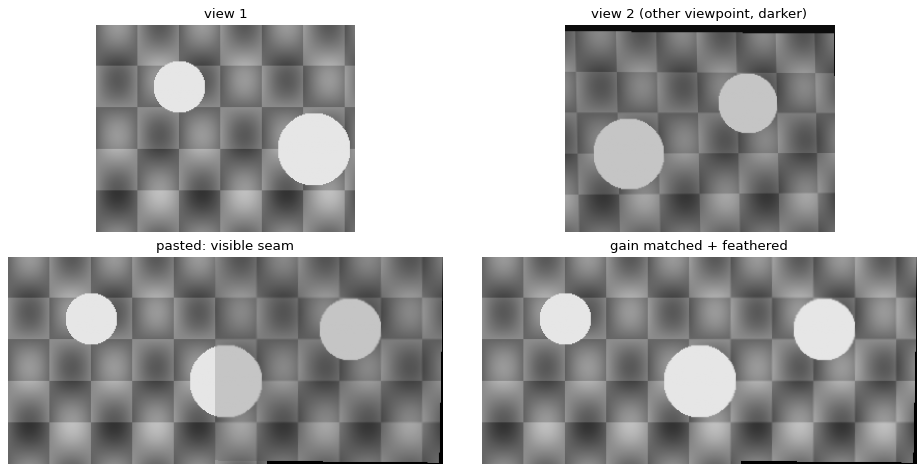

In [5]:
def warp(u, Hinv, shape):
    """g(p) = u(Hinv p), bilinear; returns image and validity mask."""
    H_, W_ = shape; yy, xx = np.mgrid[:H_, :W_]
    q = from_h(np.c_[xx.ravel(), yy.ravel(), np.ones(xx.size)] @ Hinv.T)
    x, y = q[:, 0], q[:, 1]; ok = (x >= 0) & (x < u.shape[1] - 1) & (y >= 0) & (y < u.shape[0] - 1)
    x0, y0 = np.floor(x).astype(int).clip(0, u.shape[1] - 2), np.floor(y).astype(int).clip(0, u.shape[0] - 2); dx, dy = x - x0, y - y0
    v = u[y0, x0] * (1 - dx) * (1 - dy) + u[y0, x0 + 1] * dx * (1 - dy) + u[y0 + 1, x0] * (1 - dx) * dy + u[y0 + 1, x0 + 1] * dx * dy
    return (v * ok).reshape(H_, W_), ok.reshape(H_, W_)

yy, xx = np.mgrid[:200, :420]
world = 0.4 + 0.2 * np.sin(xx / 13) * np.cos(yy / 17) + 0.15 * ((xx // 40 + yy // 40) % 2)
for cx, cy, r in [(80, 60, 25), (210, 120, 35), (330, 70, 30)]:
    world[(xx - cx) ** 2 + (yy - cy) ** 2 < r * r] = 0.9
view1 = world[:, :250]
H12 = np.array([[1.0, 0.02, -150], [0.01, 1.0, 5], [1e-4, 0, 1.0]])           # world -> view 2 coordinates
view2, _ = warp(world, np.linalg.inv(H12), (200, 260)); view2 = 0.8 * view2 + 0.05   # different exposure

pano_shape = (200, 420)
p1 = np.zeros(pano_shape); m1 = np.zeros(pano_shape, bool); p1[:, :250] = view1; m1[:, :250] = True
p2, m2 = warp(view2, H12, pano_shape)                                       # inverse warping: pano pixel -> view 2
pasted = np.where(m2 & ~m1, p2, p1)
pasted[m1 & m2] = np.where(xx[m1 & m2] < 200, p1[m1 & m2], p2[m1 & m2])    # hard cut inside the overlap

ov = m1 & m2
gain, offset = np.polyfit(p2[ov], p1[ov], 1)
p2c = gain * p2 + offset
w1 = np.clip((250 - xx) / 60, 0, 1) * m1; w2 = np.clip((xx - 150) / 60, 0, 1) * m2
blended = (w1 * p1 + w2 * p2c) / np.maximum(w1 + w2, 1e-9)
print(f"exposure fit in the overlap: view1 ≈ {gain:.3f} · view2 + {offset:.3f}")
print(f"mean |error| vs the true scene: hard seam {np.abs(pasted - world)[m1 | m2].mean():.4f}, gain + feather {np.abs(blended - world)[m1 | m2].mean():.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
axes[0, 0].imshow(view1, cmap="gray", vmin=0, vmax=1); axes[0, 0].set_title("view 1")
axes[0, 1].imshow(view2, cmap="gray", vmin=0, vmax=1); axes[0, 1].set_title("view 2 (other viewpoint, darker)")
axes[1, 0].imshow(pasted, cmap="gray", vmin=0, vmax=1); axes[1, 0].set_title("pasted: visible seam")
axes[1, 1].imshow(blended, cmap="gray", vmin=0, vmax=1); axes[1, 1].set_title("gain matched + feathered")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()